# 00 · Looking at the MVTec AD data

**Goal:** check that the dataset is complete, see what the images and defects look like, and
collect the facts we need to choose the 5 starting categories.

Nothing here trains a model. In computer vision, looking at the data comes first: image size,
colour and how big the defects are decide which methods can work and where they will struggle.

Every table below is also saved as a CSV in `results/` (file names start with `stage0_`).

**Decisions made from this notebook (2026-11-23):** start with bottle, screw, transistor,
carpet and grid (section 10), and resize every image to 256 × 256 **without** a centre crop
(section 8).

*Images shown here are from MVTec AD (Bergmann et al., CVPR 2019), licensed CC BY-NC-SA 4.0,
non-commercial use only.*

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from PIL import Image

from inspection.config import load_config, project_path
from inspection.data import check_structure, index_dataset
from inspection.device import get_device, set_seed

config = load_config()
set_seed(config["seed"])
rng = np.random.default_rng(config["seed"])  # picks sample images: same picks on every run

DATA_DIR = project_path(config["paths"]["data_dir"])
RESULTS_DIR = project_path(config["paths"]["results_dir"])
RESIZE = config["image"]["resize"]  # images are resized to RESIZE x RESIZE
CROP = config["image"]["crop"]      # None: no centre crop (decision in section 8)
MODEL_SIDE = CROP or RESIZE         # side of the image the model actually sees
STUDIED_CROP = 224                  # the PatchCore paper's centre crop, studied in section 8
KIND = {c: "object" for c in config["dataset"]["objects"]} | {
    c: "texture" for c in config["dataset"]["textures"]
}

# Chart style: quiet axes and grid, fixed colours (objects = blue, textures = orange).
COLOR = {"object": "#2a78d6", "texture": "#eb6834"}
MASK_COLOR = "#e34948"  # outline of the ground-truth defect mask
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False,
    "font.size": 10, "axes.titlesize": 11,
})
pd.set_option("display.max_colwidth", None)

print("device:", get_device())
index = index_dataset(DATA_DIR)
index["kind"] = index["category"].map(KIND)
print(f"{len(index)} images indexed from {DATA_DIR.relative_to(project_path('.'))}/")
index[["category", "split", "defect_type", "label"]].sample(5, random_state=config["seed"])

device: mps
5354 images indexed from data/mvtec_ad/


,category,split,defect_type,label
5010,zipper,train,good,0
1650,grid,train,good,0
401,cable,train,good,0
4222,toothbrush,train,good,0
1684,grid,test,bent,1


## 1. What an image is to the computer

For a computer, an image is a grid of numbers. A colour image has the shape
**height × width × 3**: for every pixel, three numbers (red, green, blue) from 0 (dark) to
255 (bright). A grayscale image has one number per pixel, so its shape is just height × width.
A defect **mask** is a grid with the same height and width, where 0 means "normal pixel" and
255 means "defect pixel"; someone at MVTec painted these by hand. In Stage 1 these grids become
PyTorch *tensors* (multi-dimensional arrays that can live on the GPU); NumPy arrays are the same
idea.

image: (900, 900, 3) uint8 | values from 25 to 255
mask:  (900, 900) uint8 | distinct values [  0 255]
top-left 3x3 pixels, red channel:
 [[255 255 255]
 [255 255 255]
 [255 255 255]]
defect pixels: 58,708 of 810,000 = 7.25% of the image


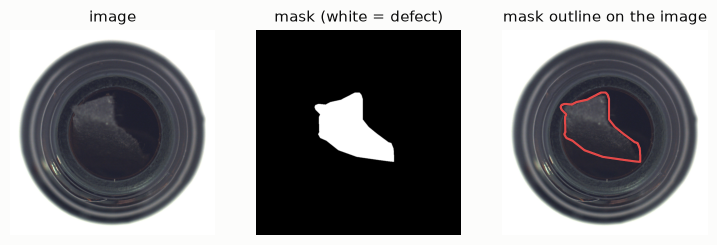

In [2]:
example = index[(index.category == "bottle") & (index.defect_type == "contamination")].iloc[0]
image = np.array(Image.open(example.image_path))
mask = np.array(Image.open(example.mask_path))

print("image:", image.shape, image.dtype, "| values from", image.min(), "to", image.max())
print("mask: ", mask.shape, mask.dtype, "| distinct values", np.unique(mask))
print("top-left 3x3 pixels, red channel:\n", image[:3, :3, 0])
print(f"defect pixels: {(mask > 0).sum():,} of {mask.size:,} = {(mask > 0).mean():.2%} of the image")

fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
axes[0].imshow(image)
axes[0].set_title("image")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("mask (white = defect)")
axes[2].imshow(image)
axes[2].contour(mask > 0, levels=[0.5], colors=MASK_COLOR, linewidths=1.5)
axes[2].set_title("mask outline on the image")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. Is the dataset complete?

Per category: training images (all good), good and defective test images, number of defect
types, and how many masks exist. MVTec publishes a total of 5,354 images.
`check_structure` (in `src/inspection/data.py`) also checks that the training folder only has
good images and that every defective image has a mask and every mask has an image.

`test_defect_share` is the share of test images that are defective. Most test sets are mostly
defective, the opposite of a real factory, where defects are rare. Image AUROC is not affected by
this balance; the thresholds in Stage 4 are.

In [3]:
train = index[index.split == "train"]
test = index[index.split == "test"]
test_defects = test[test.label == 1]

counts = pd.DataFrame({
    "kind": pd.Series(KIND),
    "train_good": train.groupby("category").size(),
    "test_good": test[test.label == 0].groupby("category").size(),
    "test_defect": test_defects.groupby("category").size(),
    "defect_types": test_defects.groupby("category")["defect_type"].nunique(),
    "masks_found": test_defects["mask_path"].map(Path.exists).groupby(test_defects["category"]).sum(),
}).rename_axis("category")
counts["total"] = counts[["train_good", "test_good", "test_defect"]].sum(axis=1)
counts["test_defect_share"] = (counts.test_defect / (counts.test_good + counts.test_defect)).round(2)
counts = counts.sort_index().sort_values("kind", kind="stable")
counts.to_csv(RESULTS_DIR / "stage0_counts.csv")

problems = check_structure(index, DATA_DIR)
print(f"Total images: {counts.total.sum():,} (MVTec publishes {config['dataset']['expected_total_images']:,})")
print("Every defective image has a mask:", bool((counts.masks_found == counts.test_defect).all()))
print("Structure problems:", problems or "none")
counts

Total images: 5,354 (MVTec publishes 5,354)
Every defective image has a mask: True
Structure problems: none


,kind,train_good,test_good,test_defect,defect_types,masks_found,total,test_defect_share
category,,,,,,,,
bottle,object,209,20,63,3,63,292,0.76
cable,object,224,58,92,8,92,374,0.61
capsule,object,219,23,109,5,109,351,0.83
hazelnut,object,391,40,70,4,70,501,0.64
metal_nut,object,220,22,93,4,93,335,0.81
pill,object,267,26,141,7,141,434,0.84
screw,object,320,41,119,5,119,480,0.74
toothbrush,object,60,12,30,1,30,102,0.71
transistor,object,213,60,40,4,40,313,0.40


## 3. Image sizes and colour

We read only each file's header, which is fast because no pixels are decoded. Mode `RGB` means
colour (3 channels), `L` means grayscale (1 channel). This matters later: pretrained networks
expect 3 channels, so grayscale images must be copied into 3 identical channels.

In [4]:
def header_info(path: Path) -> tuple[int, int, str]:
    # Width, height and colour mode from the file header only (no pixel decoding).
    with Image.open(path) as im:
        return im.width, im.height, im.mode


index[["width", "height", "mode"]] = pd.DataFrame(
    [header_info(p) for p in index.image_path], index=index.index
)
index["size"] = index.width.astype(str) + "×" + index.height.astype(str)

defect_rows = index[index.label == 1]
mask_info = pd.DataFrame(
    [header_info(p) for p in defect_rows.mask_path],
    columns=["mask_width", "mask_height", "mask_mode"], index=defect_rows.index,
)
mask_size_mismatch = int(((mask_info.mask_width != defect_rows.width)
                          | (mask_info.mask_height != defect_rows.height)).sum())

sizes = index.groupby("category").agg(
    kind=("kind", "first"),
    image_size=("size", lambda s: ", ".join(sorted(s.unique()))),
    colour_mode=("mode", lambda s: ", ".join(sorted(s.unique()))),
)
sizes = sizes.sort_index().sort_values("kind", kind="stable")
sizes.to_csv(RESULTS_DIR / "stage0_image_sizes.csv")

print("All images square:", bool((index.width == index.height).all()))
print(f"Image sides range from {index.width.min()} to {index.width.max()} px")
print("Masks whose size differs from their image:", mask_size_mismatch)
print("Mask colour modes:", mask_info.mask_mode.value_counts().to_dict())
sizes

All images square: True
Image sides range from 700 to 1024 px
Masks whose size differs from their image: 0
Mask colour modes: {'L': 1258}


,kind,image_size,colour_mode
category,,,
bottle,object,900×900,RGB
cable,object,1024×1024,RGB
capsule,object,1000×1000,RGB
hazelnut,object,1024×1024,RGB
metal_nut,object,700×700,RGB
pill,object,800×800,RGB
screw,object,1024×1024,L
toothbrush,object,1024×1024,RGB
transistor,object,1024×1024,RGB


## 4. Defect types

Each category has its own defect types. Some are *structural* (a crack, a hole, a scratch: the
local pixels look wrong). Others are *logical*: every part looks normal but something is
missing, swapped or in the wrong place (e.g. `cable_swap`, `missing_wire`, `misplaced`). Logical
defects are expected to be harder for methods that compare small patches.

In [5]:
defect_types = (test_defects.groupby(["category", "defect_type"]).size()
                .rename("n_images").reset_index())
defect_types.insert(1, "kind", defect_types.category.map(KIND))
defect_types.to_csv(RESULTS_DIR / "stage0_defect_types.csv", index=False)

print(f"{len(defect_types)} defect types in total")
(defect_types.assign(entry=lambda d: d.defect_type + " (" + d.n_images.astype(str) + ")")
 .groupby("category")["entry"].agg(", ".join).to_frame("defect types (number of images)"))

73 defect types in total


,defect types (number of images)
category,
bottle,"broken_large (20), broken_small (22), contamination (21)"
cable,"bent_wire (13), cable_swap (12), combined (11), cut_inner_insulation (14), cut_outer_insulation (10), missing_cable (12), missing_wire (10), poke_insulation (10)"
capsule,"crack (23), faulty_imprint (22), poke (21), scratch (23), squeeze (20)"
carpet,"color (19), cut (17), hole (17), metal_contamination (17), thread (19)"
grid,"bent (12), broken (12), glue (11), metal_contamination (11), thread (11)"
hazelnut,"crack (18), cut (17), hole (18), print (17)"
leather,"color (19), cut (19), fold (17), glue (19), poke (18)"
metal_nut,"bent (25), color (22), flip (23), scratch (23)"
pill,"color (25), combined (17), contamination (21), crack (26), faulty_imprint (19), pill_type (9), scratch (24)"


## 5. How big are the defects?

The mask marks exactly which pixels are defective, so the share of white pixels is the defect's
size relative to the whole image.

Size matters because of our preprocessing (`config.yaml`): every image is shrunk to
**256 × 256** before it goes into a model. A 1024 px image shrinks by 4× per side, so a defect
of 400 pixels becomes about 25 pixels (5 × 5). We compute two things per defective image:

- `px_in_model_input`: how many pixels of the 256 × 256 model input the defect covers.
- `share_lost_by_crop`: the part of the defect that a **224 × 224 centre crop** would throw
  away. Many papers (PatchCore among them) keep only that centre. If this share is 100%, the
  image is labelled "defective" but a model that crops cannot see the defect. Section 8 uses
  this number to decide whether we crop.


In [6]:
def defect_size(mask_path: Path) -> dict[str, float]:
    # All images are square (checked above), so one scale factor covers both sides.
    mask = np.array(Image.open(mask_path).convert("L")) > 127
    side = mask.shape[0]
    scale = RESIZE / side  # e.g. 256 / 1024 = 0.25

    def inside_centre(crop: int) -> int:
        # Defect pixels (counted at original resolution) inside a centre crop of `crop` px.
        border = round((RESIZE - crop) / 2 / scale)  # crop border per side, in original pixels
        return int(mask[border:side - border, border:side - border].sum())

    total = int(mask.sum())
    return {
        "area_share": total / mask.size,
        "px_in_model_input": inside_centre(MODEL_SIDE) * scale**2,
        "share_lost_by_crop": 1 - inside_centre(STUDIED_CROP) / total if total else np.nan,
    }


start = time.perf_counter()
defects = index[index.label == 1].copy()
defects[["area_share", "px_in_model_input", "share_lost_by_crop"]] = pd.DataFrame(
    [defect_size(p) for p in defects.mask_path], index=defects.index
)
defects["image"] = defects.image_path.map(lambda p: str(p.relative_to(DATA_DIR)))
print(f"Measured {len(defects)} masks in {time.perf_counter() - start:.1f} s")
print("Empty masks (defective image, nothing marked):", int((defects.area_share == 0).sum()))

defects[["category", "kind", "defect_type", "image", "area_share", "px_in_model_input",
         "share_lost_by_crop"]].to_csv(RESULTS_DIR / "stage0_defect_sizes.csv", index=False)

TINY_PX = 64  # an 8 x 8 square in the model input
size_summary = defects.groupby("category").agg(
    kind=("kind", "first"),
    n_defect_images=("area_share", "size"),
    median_area_pct=("area_share", lambda s: 100 * s.median()),
    min_area_pct=("area_share", lambda s: 100 * s.min()),
    max_area_pct=("area_share", lambda s: 100 * s.max()),
    tiny_under_64px=("px_in_model_input", lambda s: int((s < TINY_PX).sum())),
    partly_cut_by_crop=("share_lost_by_crop", lambda s: int((s > 0).sum())),
    over_half_cut=("share_lost_by_crop", lambda s: int((s > 0.5).sum())),
    fully_cut=("share_lost_by_crop", lambda s: int((s >= 1).sum())),
).sort_values("median_area_pct")
size_summary.round(3).to_csv(RESULTS_DIR / "stage0_defect_size_summary.csv")
size_summary.round(3)

Measured 1258 masks in 1.0 s
Empty masks (defective image, nothing marked): 0


,kind,n_defect_images,median_area_pct,min_area_pct,max_area_pct,tiny_under_64px,partly_cut_by_crop,over_half_cut,fully_cut
category,,,,,,,,,
screw,object,119,0.288,0.099,1.011,0,12,1,0
capsule,object,109,0.430,0.037,8.079,5,3,0,0
leather,texture,92,0.462,0.089,6.859,1,8,0,0
grid,texture,57,0.601,0.188,3.582,0,22,1,1
pill,object,141,1.033,0.050,41.004,7,5,0,0
toothbrush,object,30,1.078,0.238,12.976,0,5,0,0
carpet,texture,89,1.476,0.165,8.017,0,11,1,0
hazelnut,object,70,1.616,0.233,27.659,0,0,0,0
transistor,object,40,2.028,0.224,49.321,0,9,0,0


Each dot below is one defective test image. The x-axis is logarithmic: each grid step is 10×
bigger, because defect sizes range over several powers of ten. The black bar is the median per
category; the dashed line marks 64 pixels (8 × 8) in the model input.

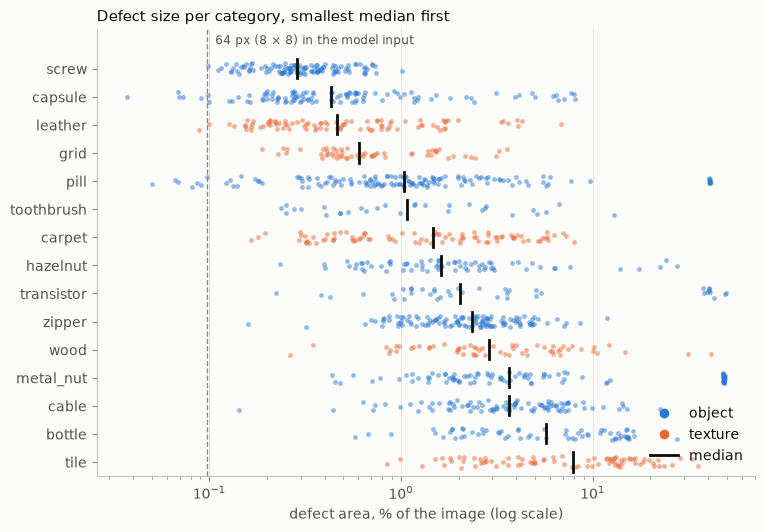

In [7]:
order = size_summary.index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 5.8))
for y, category in enumerate(order):
    values = 100 * defects.loc[defects.category == category, "area_share"]
    jitter = rng.uniform(-0.2, 0.2, len(values))
    ax.scatter(values, y + jitter, s=12, color=COLOR[KIND[category]], alpha=0.5, linewidths=0)
    ax.plot([values.median()] * 2, [y - 0.34, y + 0.34], color="#0b0b0b", lw=2)

tiny_pct = 100 * TINY_PX / MODEL_SIDE**2
ax.axvline(tiny_pct, color="#898781", lw=1, ls="--")
ax.text(tiny_pct, -1.0, "  64 px (8 × 8) in the model input", fontsize=8.5, color="#52514e",
        va="center")
ax.set_xscale("log")
ax.set_yticks(range(len(order)), order)
ax.set_ylim(len(order) - 0.5, -1.4)  # smallest median at the top, room above for the line label
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("defect area, % of the image (log scale)")
ax.set_title("Defect size per category, smallest median first", loc="left")
ax.legend(handles=[
    Line2D([], [], marker="o", ls="", color=COLOR["object"], label="object"),
    Line2D([], [], marker="o", ls="", color=COLOR["texture"], label="texture"),
    Line2D([], [], color="#0b0b0b", lw=2, label="median"),
], loc="lower right")
plt.show()

The 10 defect types with the smallest median size:

In [8]:
by_type = (defects.groupby(["category", "defect_type"])
           .agg(n_images=("area_share", "size"),
                median_area_pct=("area_share", lambda s: 100 * s.median()),
                median_px_in_model_input=("px_in_model_input", "median"))
           .sort_values("median_area_pct"))
by_type.head(10).round(3)

n_images  median_area_pct  \
category defect_type                                    
pill     color                    25            0.173   
capsule  poke                     21            0.225   
leather  poke                     18            0.227   
         color                    19            0.248   
screw    scratch_head             24            0.248   
         thread_side              23            0.259   
capsule  faulty_imprint           22            0.278   
screw    manipulated_front        24            0.299   
capsule  crack                    23            0.304   
screw    scratch_neck             25            0.305   

                            median_px_in_model_input  
category defect_type                                  
pill     color                               113.664  
capsule  poke                                147.653  
leather  poke                                148.594  
         color                               162.438  
screw    scratch_head                        162.625  
         thread_side                         170.062  
capsule  faulty_imprint                      182.190  
screw    manipulated_front                   195.812  
capsule  crack                               199.426  
screw    scratch_neck                        199.875

## 6. Good vs defective images

For each category: one good test image and three defective ones (three different defect types
where the category has them), with the mask outline in red. Images are shrunk to 256 px for
display only.

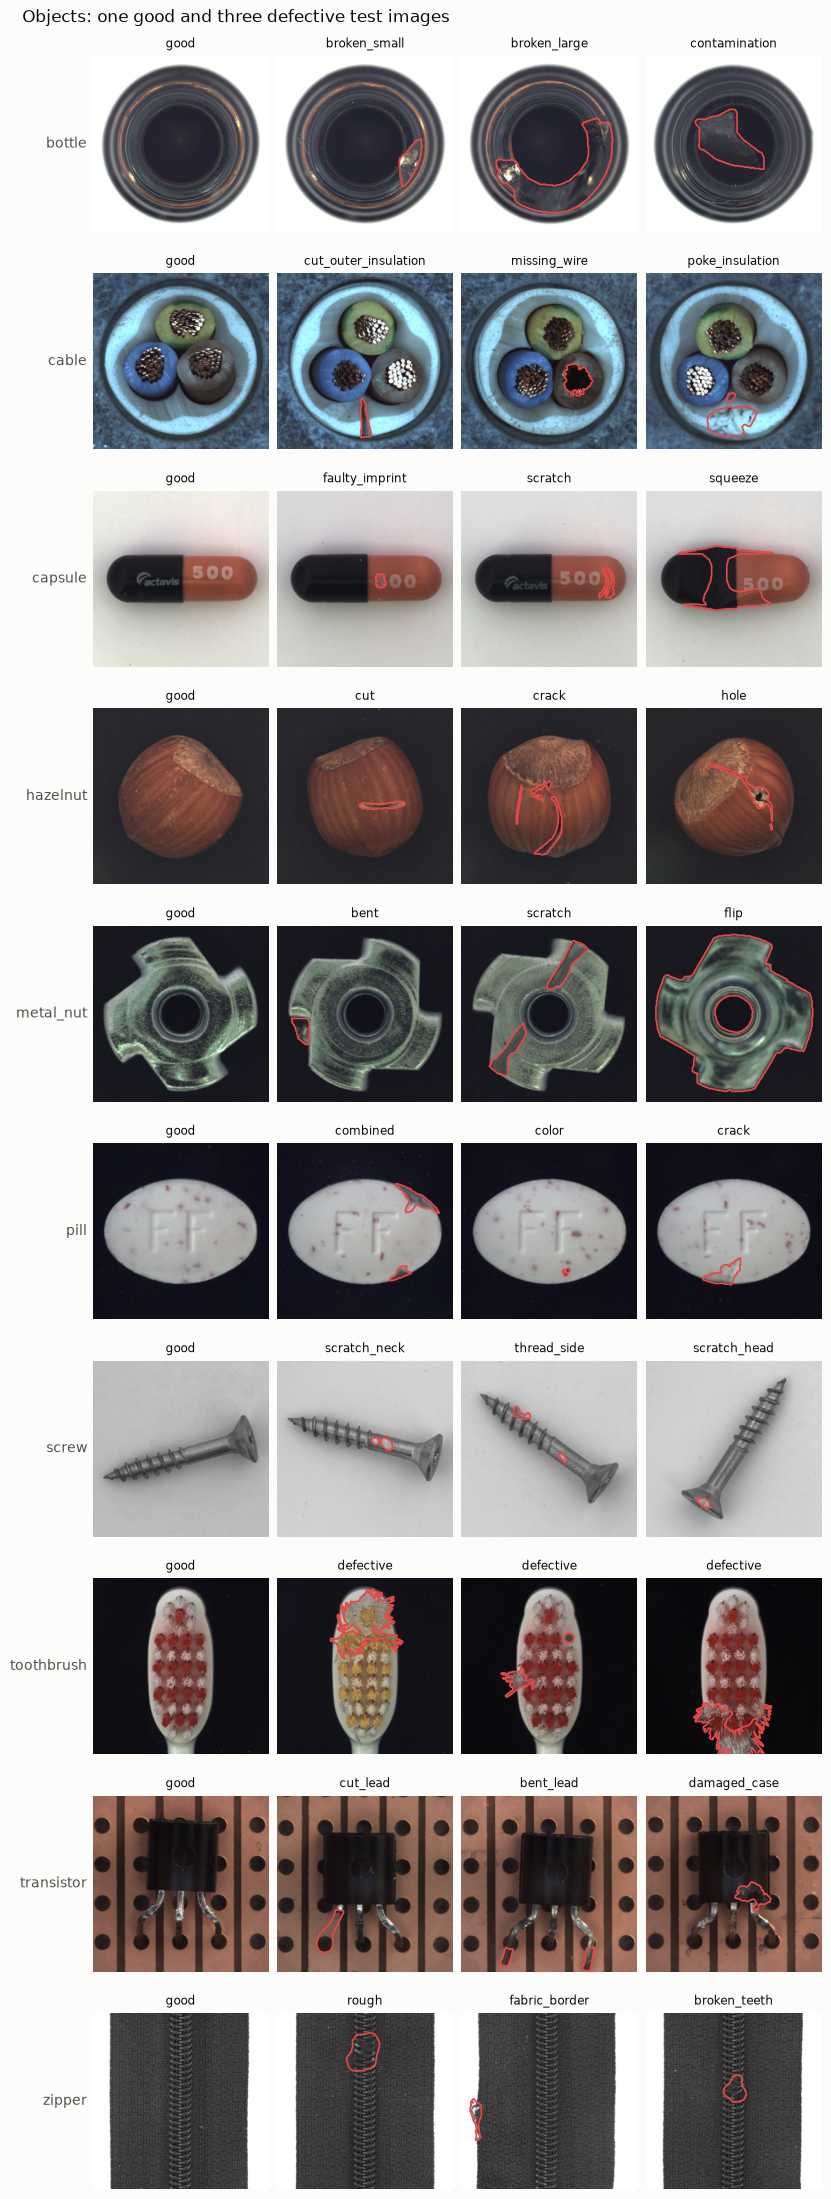

In [9]:
THUMB = 256


def thumbnail(path: Path, resample: Image.Resampling) -> np.ndarray:
    with Image.open(path) as im:
        return np.array(im.resize((THUMB, THUMB), resample))


def show_image(ax: plt.Axes, row: pd.Series, title: str) -> None:
    # Draw one image; if it has a mask, outline the defect in red.
    img = thumbnail(row.image_path, Image.Resampling.LANCZOS)
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(img)
    if isinstance(row.mask_path, Path):
        # BOX averages pixels, so even a 1-pixel-wide scratch leaves a value > 0 to outline.
        m = thumbnail(row.mask_path, Image.Resampling.BOX)
        ax.contour(m > 0, levels=[0.5], colors=MASK_COLOR, linewidths=1.2)
    ax.set_title(title, fontsize=8.5)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def sample_grid(categories: list[str], title: str, n_defects: int = 3) -> None:
    fig, axes = plt.subplots(len(categories), 1 + n_defects, layout="constrained",
                             figsize=(2.05 * (1 + n_defects), 2.2 * len(categories)))
    for r, category in enumerate(categories):
        rows = index[(index.category == category) & (index.split == "test")]
        good = rows[rows.label == 0]
        show_image(axes[r, 0], good.iloc[rng.integers(len(good))], "good")
        types = rng.permutation(rows.loc[rows.label == 1, "defect_type"].unique())
        used: set[int] = set()
        for c in range(n_defects):
            defect_type = types[c % len(types)]  # toothbrush has one type: show 3 different images
            candidates = rows[(rows.defect_type == defect_type) & ~rows.index.isin(used)]
            pick = candidates.iloc[rng.integers(len(candidates))]
            used.add(pick.name)
            show_image(axes[r, c + 1], pick, defect_type)
        axes[r, 0].set_ylabel(category, rotation=0, ha="right", va="center", fontsize=10)
    fig.suptitle(title, x=0.02, ha="left")
    plt.show()


sample_grid(config["dataset"]["objects"], "Objects: one good and three defective test images")

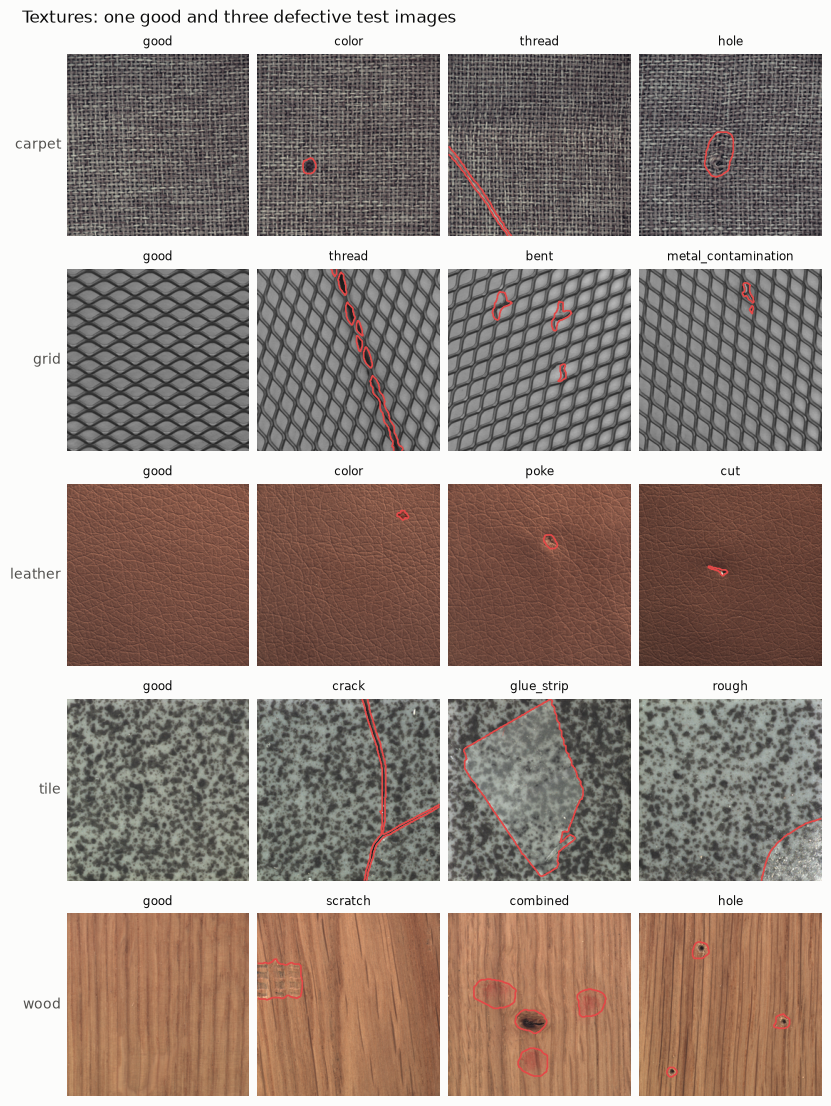

In [10]:
sample_grid(config["dataset"]["textures"], "Textures: one good and three defective test images")

## 7. The smallest defect in each category

Left: the whole image with the mask outline. Right: a zoom on the defect. These are the cases a
method must still catch; after shrinking to 256 px some of them are only a few pixels.

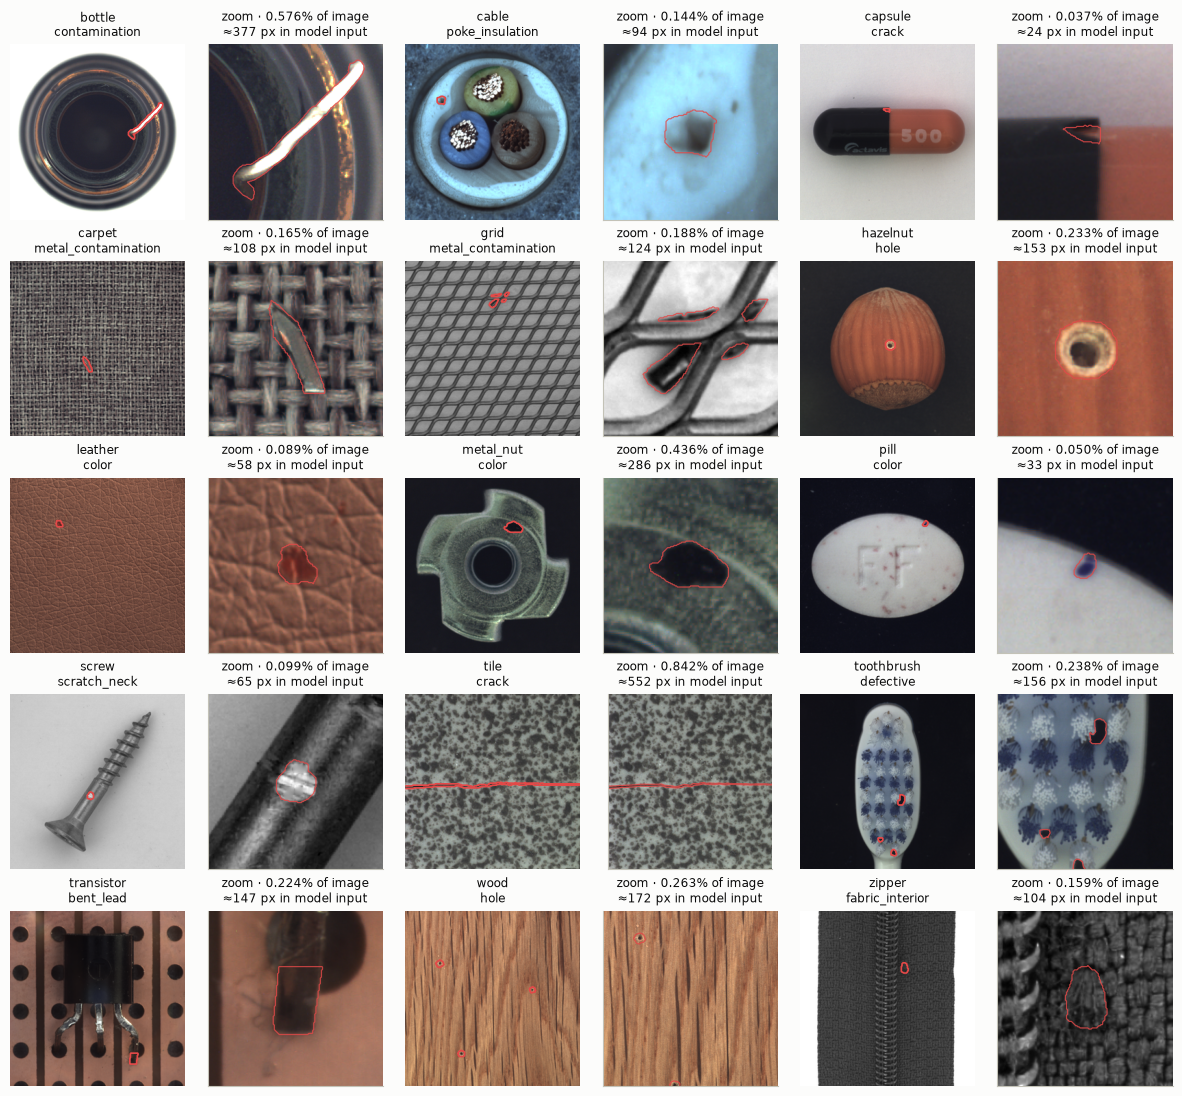

In [11]:
smallest = defects.loc[defects[defects.area_share > 0].groupby("category")["area_share"].idxmin()]
fig, axes = plt.subplots(5, 6, figsize=(12, 11))
for i, (_, row) in enumerate(smallest.iterrows()):
    ax_full, ax_zoom = axes.flat[2 * i], axes.flat[2 * i + 1]
    show_image(ax_full, row, f"{row.category}\n{row.defect_type}")

    mask = np.array(Image.open(row.mask_path).convert("L")) > 127
    img = np.array(Image.open(row.image_path))
    ys, xs = np.nonzero(mask)
    cy, cx = int(ys.mean()), int(xs.mean())
    half = max(80, (ys.max() - ys.min()) // 2 + 24, (xs.max() - xs.min()) // 2 + 24)
    y0, x0 = max(cy - half, 0), max(cx - half, 0)
    zoom_img, zoom_mask = img[y0:cy + half, x0:cx + half], mask[y0:cy + half, x0:cx + half]
    ax_zoom.imshow(zoom_img, cmap="gray" if zoom_img.ndim == 2 else None)
    ax_zoom.contour(zoom_mask, levels=[0.5], colors=MASK_COLOR, linewidths=0.9, alpha=0.8)
    ax_zoom.set_title(f"zoom · {100 * row.area_share:.3f}% of image\n"
                      f"≈{row.px_in_model_input:.0f} px in model input", fontsize=8.5)
    ax_zoom.set_xticks([])
    ax_zoom.set_yticks([])
fig.tight_layout()
plt.show()

## 8. Should we keep the centre crop?

A 224 × 224 centre crop of the 256 × 256 image removes a band of 6.25% on each edge. Below are
the defective images that would lose more than half of their defect area to that band. The
dashed white square is what the crop would keep.


Defective images that would lose > 50% of the defect to a 224 crop: 7; all of it: 1


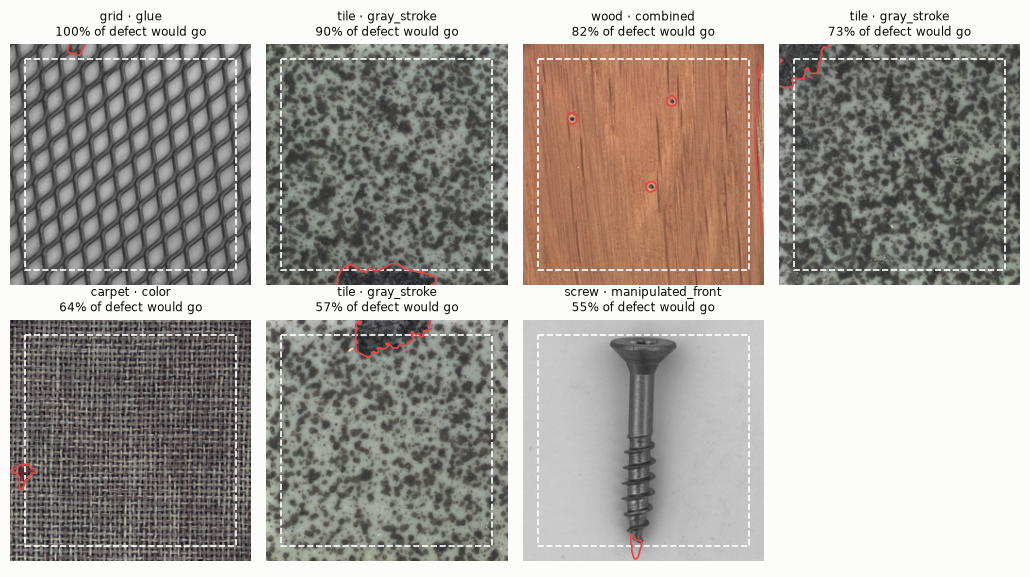

In [12]:
cut = defects[defects.share_lost_by_crop > 0.5].sort_values("share_lost_by_crop", ascending=False)
print(f"Defective images that would lose > 50% of the defect to a {STUDIED_CROP} crop: "
      f"{len(cut)}; all of it: {int((defects.share_lost_by_crop >= 1).sum())}")

if len(cut):
    shown = cut.head(8)
    n_cols = 4
    n_rows = int(np.ceil(len(shown) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.9 * n_rows), squeeze=False)
    band = THUMB * (RESIZE - STUDIED_CROP) / 2 / RESIZE  # crop border in thumbnail pixels
    for ax, (_, row) in zip(axes.flat, shown.iterrows()):
        show_image(ax, row, f"{row.category} · {row.defect_type}\n"
                            f"{row.share_lost_by_crop:.0%} of defect would go")
        ax.add_patch(plt.Rectangle((band - 0.5, band - 0.5), THUMB - 2 * band, THUMB - 2 * band,
                                   fill=False, ls="--", lw=1.2, ec="#ffffff"))
    for ax in axes.flat[len(shown):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()

**Decision (2026-11-23): no centre crop.** We resize to 256 × 256 and use the whole image,
so every labelled defect stays visible to the model and every mask pixel counts in the pixel
metrics. With the crop, an image like the first one above would count as "defective" in the
evaluation even though the model never sees the defect.


## 9. Key numbers from this notebook

In [13]:
grayscale = sizes.index[sizes.colour_mode == "L"].tolist()
print(f"Images: {len(index):,} (expected {config['dataset']['expected_total_images']:,}); "
      f"structure problems: {len(problems)}")
print(f"Categories: {len(counts)} ({(counts.kind == 'object').sum()} objects, "
      f"{(counts.kind == 'texture').sum()} textures); defect types: {len(defect_types)}")
print(f"Grayscale categories: {grayscale}")
print(f"Image sides: {index.width.min()}–{index.width.max()} px, all square")
print(f"Defect area: median {100 * defects.area_share.median():.2f}% of the image, "
      f"smallest {100 * defects.area_share.min():.4f}%, largest {100 * defects.area_share.max():.1f}%")
print(f"Tiny defects (< {TINY_PX} px in the {MODEL_SIDE} × {MODEL_SIDE} model input): "
      f"{int((defects.px_in_model_input < TINY_PX).sum())} of {len(defects)}")
print(f"Defects a {STUDIED_CROP} centre crop would cut: {int((defects.share_lost_by_crop > 0).sum())}; "
      f"> 50% cut: {int((defects.share_lost_by_crop > 0.5).sum())}; "
      f"fully cut: {int((defects.share_lost_by_crop >= 1).sum())}")

Images: 5,354 (expected 5,354); structure problems: 0
Categories: 15 (10 objects, 5 textures); defect types: 73
Grayscale categories: ['screw', 'zipper', 'grid']
Image sides: 700–1024 px, all square
Defect area: median 1.54% of the image, smallest 0.0371%, largest 49.3%
Tiny defects (< 64 px in the 256 × 256 model input): 13 of 1258
Defects a 224 centre crop would cut: 232; > 50% cut: 7; fully cut: 1


## 10. What this means for the next stages

- **The data is complete**, and the folder structure matches what `src/inspection/data.py`
  expects.
- **Screw, zipper and grid are grayscale.** Pretrained networks expect 3 channels, so these
  images will be converted to RGB when loaded (the same gray value copied into all three).
- **Images are shrunk about 3–4× per side.** The smallest defects then cover only a few dozen
  pixels of the model input (mostly pill `color` and capsule `crack`). Methods that work on
  coarse feature maps may miss them.
- **We do not crop.** A 224 centre crop would cut part of many defects (most in tile, zipper and
  metal_nut) and remove one (grid `glue`) completely. We resize to 256 × 256 and keep the whole
  image. The price is about 30% more compute than 224 × 224 (256² / 224² ≈ 1.31), and our
  numbers cannot be compared one-to-one with papers that crop.
- **Some defects are logical, not local:** metal_nut `flip`, pill `pill_type`, transistor
  `misplaced`. Their masks cover the whole object (the 40–50% clusters in the size plot). Every
  small patch of such an image can look normal, so patch-based methods may find them harder.
- **Starting categories: bottle, screw, transistor, carpet, grid.** Three objects and two
  textures, from easy to hard: bottle has large defects; screw has the smallest defects and is
  grayscale; transistor has `misplaced`, a defect that covers the whole object, and the only
  test set that is mostly good; carpet is an irregular texture; grid is a regular, grayscale
  texture with many defects near the image edge.
- **Test sets are mostly defective**, the opposite of a real factory. AUROC does not depend on
  this ratio; the Stage 4 thresholds are set on good training images only, as planned.